# ATDL Project Explorer and Dataset QA

**Project:** Class-Imbalance-Aware Steel Surface Defect Detection Using Pretrained YOLO Models  
**Dataset:** NEU-DET | **Task:** detect and localize six steel-surface defect classes

Use this notebook in VS Code to understand the current workspace, inspect its folders and artifacts, verify the Phase 2 YOLO dataset, and preview real training annotations. It only reads project files and displays results; it does not train a model or change the dataset.

## Open and run in VS Code

1. Open the project folder (`atdl_final_project`) in VS Code, then open this `.ipynb` file.
2. Select the project virtual environment as the notebook kernel: `.venv/bin/python` on Linux/macOS, or `.venv\Scripts\python.exe` on Windows.
3. If VS Code says the kernel is unavailable, open the project terminal and run `python -m pip install -r requirements-local.txt`, then select the `.venv` kernel and run the cells from top to bottom.

The notebook locates the project root whether the kernel starts in the project folder or in `notebook/`.


## 1. Locate the project and load the small set of analysis libraries

The analysis cells use packages listed in `requirements-local.txt`. PyTorch and Ultralytics are not needed for this dataset inspection notebook.

In [1]:
from pathlib import Path
import json
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display

# Find the workspace root without relying on VS Code's current working directory.
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "requirements-local.txt").is_file() and (p / "notebook").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Open the atdl_final_project folder in VS Code."
    )

DATA_ROOT = PROJECT_ROOT / "data"
RESULTS_ROOT = PROJECT_ROOT / "results"
NOTEBOOK_ROOT = PROJECT_ROOT / "notebook"

phase2_summary_path = RESULTS_ROOT / "phase2" / "phase2_dataset_summary.json"
phase2_summary = json.loads(phase2_summary_path.read_text(encoding="utf-8")) if phase2_summary_path.exists() else {}
CLASS_NAMES = phase2_summary.get("class_names", [
    "crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"
])
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}

print(f"Project root: {PROJECT_ROOT}")
print(f"Classes ({len(CLASS_NAMES)}): {', '.join(CLASS_NAMES)}")
print(f"Python: {os.sys.version.split()[0]}")
print(f"pandas: {pd.__version__} | NumPy: {np.__version__}")


Project root: .
Classes (6): crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches
Python: 3.14.9
pandas: 3.1.1 | NumPy: 2.5.4


## 2. Inventory the workspace folders

This summarizes every project folder and file extension while skipping only virtual-environment and Python cache folders. It counts files without printing thousands of image or label filenames.

In [2]:
SKIP_DIRS = {".git", ".venv", "venv", "__pycache__", ".ipynb_checkpoints"}
direct_file_counts = {}
extension_counts = Counter()

for current, directories, files in os.walk(PROJECT_ROOT):
    directories[:] = sorted(d for d in directories if d not in SKIP_DIRS)
    current_path = Path(current)
    rel = current_path.relative_to(PROJECT_ROOT)
    direct_file_counts[rel] = len(files)
    for filename in files:
        suffix = Path(filename).suffix.lower() or "[no extension]"
        extension_counts[suffix] += 1

recursive_file_counts = dict(direct_file_counts)
for rel in sorted(direct_file_counts, key=lambda p: len(p.parts), reverse=True):
    if rel.parts:
        recursive_file_counts[rel.parent] = recursive_file_counts.get(rel.parent, 0) + recursive_file_counts[rel]

folder_rows = []
for rel in sorted(direct_file_counts, key=lambda p: (len(p.parts), str(p))):
    folder_rows.append({
        "folder": "." if str(rel) == "." else rel.as_posix(),
        "files_here": direct_file_counts[rel],
        "files_in_folder_tree": recursive_file_counts[rel],
    })
folder_inventory = pd.DataFrame(folder_rows)
display(folder_inventory)

print("\nFile types (excluding skipped cache/environment folders):")
display(pd.DataFrame(extension_counts.most_common(), columns=["extension", "file_count"]))


,folder,files_here,files_in_folder_tree
0,.,4,49789
1,archive,0,23164
2,configs,1,1
3,data,1,26311
4,dataset,1,1
...,...,...,...
198,archive/pre_duplicate_group_split/data/imbalan...,1470,1470
199,archive/pre_duplicate_group_split/data/imbalan...,2062,2062
200,archive/pre_duplicate_group_split/data/imbalan...,2062,2062
201,archive/pre_duplicate_group_split/data/imbalan...,2718,2718



File types (excluding skipped cache/environment folders):


,extension,file_count
0,.jpg,24855
1,.txt,22742
2,.xml,1800
3,.png,229
4,.csv,48
5,.json,33
6,.yaml,27
7,.pt,25
8,.cache,16
9,.ipynb,8


## 3. What this project is studying

The research compares a pretrained YOLO detector on NEU-DET with controlled class-imbalance training data and imbalance-aware methods. The experimental imbalance is introduced deliberately in the **training split**. Validation and test data should remain fixed, and the test split should be held back until final evaluation.

The six classes have stable IDs from 0 to 5. Phase 1 audited the supplied dataset and XML annotations; Phase 2 converted annotations to normalized YOLO labels and created image-level train/validation/test splits. Later phases are intended to train a baseline, create long-tail variants, compare sampling/augmentation methods, evaluate results, and provide an inference demo.

## 4. Read the saved audit summaries

These summaries are existing project outputs. The values below are read from the saved reports; they are not estimates.

In [3]:
phase1_path = RESULTS_ROOT / "tables" / "phase1_dataset_audit.json"
phase1 = json.loads(phase1_path.read_text(encoding="utf-8")) if phase1_path.exists() else {}

summary_rows = []
if phase1:
    image_stats = phase1.get("image_statistics", {})
    annotation_stats = phase1.get("annotation_statistics", {})
    summary_rows.extend([
        {"measure": "Valid source images", "value": image_stats.get("total_valid_images")},
        {"measure": "Corrupted source images", "value": image_stats.get("corrupted_images")},
        {"measure": "Exact duplicate groups", "value": image_stats.get("exact_duplicate_groups")},
        {"measure": "Perceptual-hash candidate pairs", "value": image_stats.get("perceptual_duplicate_candidate_pairs")},
        {"measure": "Parsed XML annotations", "value": annotation_stats.get("successfully_parsed_xml")},
        {"measure": "Annotated defect objects", "value": annotation_stats.get("total_annotated_objects")},
    ])
if phase2_summary:
    summary_rows.extend([
        {"measure": "Phase 2 conversion status", "value": phase2_summary.get("validation_status")},
        {"measure": "Images converted", "value": phase2_summary.get("image_count_converted")},
        {"measure": "YOLO objects converted", "value": phase2_summary.get("object_count_converted")},
        {"measure": "Split method", "value": phase2_summary.get("split_method")},
        {"measure": "Split seed", "value": phase2_summary.get("random_seed")},
    ])

display(pd.DataFrame(summary_rows))
if not summary_rows:
    print("No saved Phase 1/2 summary was found. Check results/tables and results/phase2.")


,measure,value
0,Valid source images,1800
1,Corrupted source images,0
2,Exact duplicate groups,1
3,Perceptual-hash candidate pairs,None
4,Parsed XML annotations,1800
5,Annotated defect objects,4189
6,Phase 2 conversion status,passed
7,Images converted,1799
8,YOLO objects converted,4186
9,Split method,reused_existing_manifest


## 5. Compare class image counts and object counts

An image can contain more than one defect class, so image-presence counts may sum to more than the number of images. Object counts count bounding boxes.

,class_id,class_name,image_presence_count,object_count
0,0,crazing,300,689
1,1,inclusion,382,1011
2,2,patches,341,878
3,3,pitted_surface,301,432
4,4,rolled-in_scale,300,628
5,5,scratches,300,548


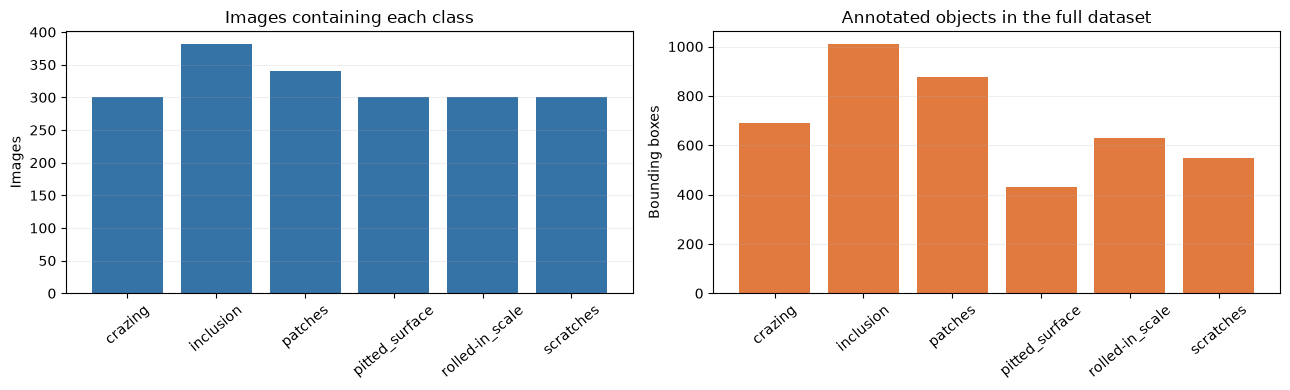

In [4]:
class_counts_path = RESULTS_ROOT / "phase2" / "class_counts_before_split.csv"
if class_counts_path.exists():
    class_counts = pd.read_csv(class_counts_path)
    display(class_counts)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].bar(class_counts["class_name"], class_counts["image_presence_count"], color="#3572A5")
    axes[0].set_title("Images containing each class")
    axes[0].set_ylabel("Images")
    axes[1].bar(class_counts["class_name"], class_counts["object_count"], color="#E07A3F")
    axes[1].set_title("Annotated objects in the full dataset")
    axes[1].set_ylabel("Bounding boxes")
    for ax in axes:
        ax.tick_params(axis="x", rotation=40)
        ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()
else:
    print(f"Missing file: {class_counts_path.relative_to(PROJECT_ROOT)}")


## 6. Check processed images, YOLO labels, and class IDs

For each split, this cell checks image/label pairing, YOLO row shape, class IDs, normalized coordinates, and the number of boxes per class. It only reads the dataset.

In [5]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
split_rows = []
object_counts_by_split = {}
label_issues = []

for split in ("train", "val", "test"):
    image_dir = DATA_ROOT / "processed" / "images" / split
    label_dir = DATA_ROOT / "processed" / "labels" / split
    images = sorted(p for p in image_dir.glob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES) if image_dir.exists() else []
    labels = sorted(label_dir.glob("*.txt")) if label_dir.exists() else []
    image_stems = [p.stem for p in images]
    label_stems = [p.stem for p in labels]
    image_stem_set, label_stem_set = set(image_stems), set(label_stems)
    class_counts = Counter()
    box_count = 0
    malformed_rows = 0

    for label_path in labels:
        for line_number, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), start=1):
            values = line.split()
            if not values:
                continue
            try:
                if len(values) != 5:
                    raise ValueError("expected five columns")
                class_id = int(values[0])
                coords = [float(value) for value in values[1:]]
                x_center, y_center, width, height = coords
                if class_id < 0 or class_id >= len(CLASS_NAMES):
                    raise ValueError("class ID outside configured class range")
                if not all(np.isfinite(coords)):
                    raise ValueError("non-finite coordinate")
                if not (0 <= x_center <= 1 and 0 <= y_center <= 1 and 0 < width <= 1 and 0 < height <= 1):
                    raise ValueError("coordinate outside normalized YOLO bounds")
                if x_center - width / 2 < -1e-6 or x_center + width / 2 > 1 + 1e-6:
                    raise ValueError("box exceeds horizontal image bounds")
                if y_center - height / 2 < -1e-6 or y_center + height / 2 > 1 + 1e-6:
                    raise ValueError("box exceeds vertical image bounds")
                class_counts[class_id] += 1
                box_count += 1
            except (TypeError, ValueError) as exc:
                malformed_rows += 1
                label_issues.append({"split": split, "label": label_path.name, "line": line_number, "issue": str(exc)})

    object_counts_by_split[split] = class_counts
    split_rows.append({
        "split": split,
        "images": len(images),
        "labels": len(labels),
        "images_missing_labels": len(image_stem_set - label_stem_set),
        "labels_missing_images": len(label_stem_set - image_stem_set),
        "boxes": box_count,
        "malformed_rows": malformed_rows,
    })

split_check = pd.DataFrame(split_rows)
display(split_check)
if label_issues:
    print("Rows that need review:")
    display(pd.DataFrame(label_issues).head(30))
else:
    print("No malformed YOLO rows found by these checks.")


,split,images,labels,images_missing_labels,labels_missing_images,boxes,malformed_rows
0,train,1257,1257,0,0,2915,0
1,val,266,266,0,0,631,0
2,test,276,276,0,0,640,0


No malformed YOLO rows found by these checks.


## 7. Confirm the saved split manifest has no image leakage

This verifies the Phase 2 manifest has one split assignment per source image and expected split names. It does not use test examples for model selection.

In [6]:
split_manifest_path = DATA_ROOT / "splits" / "phase2_image_split.csv"
if split_manifest_path.exists():
    split_manifest = pd.read_csv(split_manifest_path)
    required_columns = {"image_path", "split"}
    missing_columns = required_columns - set(split_manifest.columns)
    if missing_columns:
        print(f"Manifest is missing columns: {sorted(missing_columns)}")
    else:
        manifest_report = pd.DataFrame([
            {"check": "Manifest rows", "result": len(split_manifest)},
            {"check": "Unique source paths", "result": split_manifest["image_path"].nunique()},
            {"check": "Exact-content groups", "result": split_manifest["sha256"].nunique() if "sha256" in split_manifest else "not recorded"},
            {"check": "Duplicate source paths", "result": int(split_manifest["image_path"].duplicated().sum())},
            {"check": "Split names", "result": ", ".join(sorted(split_manifest["split"].dropna().astype(str).unique()))},
        ])
        display(manifest_report)
        display(split_manifest["split"].value_counts().rename_axis("split").reset_index(name="raw source files"))
        if "sha256" in split_manifest:
            unique_contents = split_manifest.drop_duplicates("sha256")
            display(unique_contents["split"].value_counts().rename_axis("split").reset_index(name="unique image contents"))
else:
    print(f"Missing file: {split_manifest_path.relative_to(PROJECT_ROOT)}")


,check,result
0,Manifest rows,1800
1,Unique source paths,1800
2,Exact-content groups,1799
3,Duplicate source paths,0
4,Split names,"test, train, val"


,split,raw source files
0,train,1258
1,test,276
2,val,266


,split,unique image contents
0,train,1257
1,test,276
2,val,266


## 8. Plot class frequencies by split

This reads the saved Phase 2 distribution report and plots both images containing a class and annotated objects.

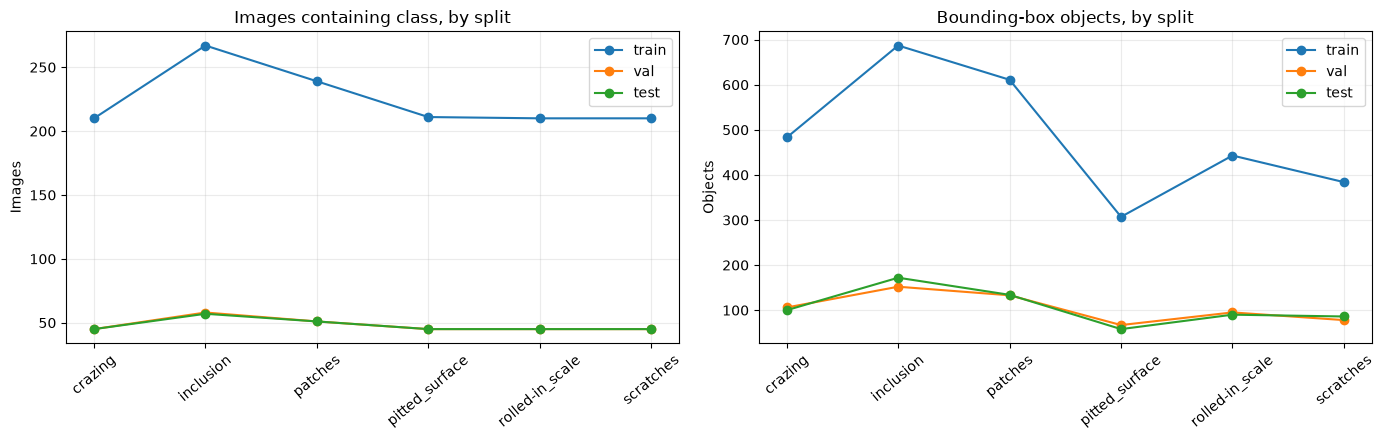

In [7]:
split_distribution_path = RESULTS_ROOT / "phase2" / "split_class_distribution.csv"
if split_distribution_path.exists():
    split_distribution = pd.read_csv(split_distribution_path)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for split in ("train", "val", "test"):
        part = split_distribution[split_distribution["split"] == split]
        axes[0].plot(part["class_name"], part["images_with_class"], marker="o", label=split)
        axes[1].plot(part["class_name"], part["object_count"], marker="o", label=split)
    axes[0].set_title("Images containing class, by split")
    axes[0].set_ylabel("Images")
    axes[1].set_title("Bounding-box objects, by split")
    axes[1].set_ylabel("Objects")
    for ax in axes:
        ax.tick_params(axis="x", rotation=40)
        ax.grid(alpha=0.25)
        ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print(f"Missing file: {split_distribution_path.relative_to(PROJECT_ROOT)}")


## 9. Preview a training image with its YOLO boxes

The default sample comes from `train`. Change `SAMPLE_SPLIT` to `val` only when you want a validation visual check. Keep the test split for final evaluation.

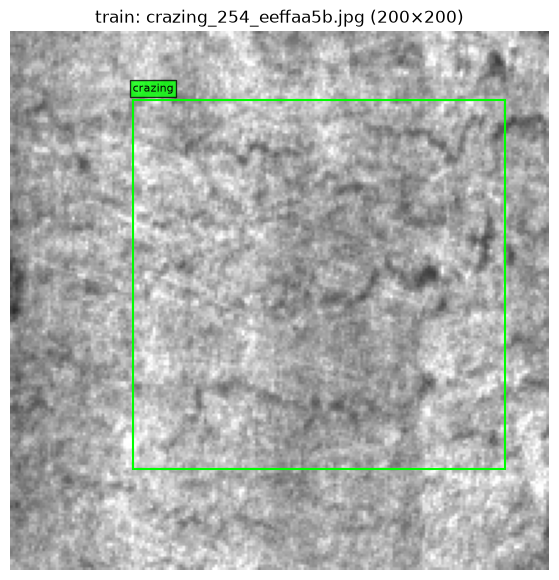

In [8]:
SAMPLE_SPLIT = "train"  # choose "train" or "val" for visual inspection
SAMPLE_SEED = 42
if SAMPLE_SPLIT not in {"train", "val"}:
    raise ValueError("For this inspection cell, SAMPLE_SPLIT must be 'train' or 'val'.")

sample_image_dir = DATA_ROOT / "processed" / "images" / SAMPLE_SPLIT
sample_label_dir = DATA_ROOT / "processed" / "labels" / SAMPLE_SPLIT
sample_images = sorted(p for p in sample_image_dir.glob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
if not sample_images:
    print(f"No processed images found in {sample_image_dir.relative_to(PROJECT_ROOT)}")
else:
    rng = np.random.default_rng(SAMPLE_SEED)
    image_path = sample_images[int(rng.integers(0, len(sample_images)))]
    label_path = sample_label_dir / f"{image_path.stem}.txt"
    image = Image.open(image_path).convert("RGB")
    width_px, height_px = image.size
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(image)
    ax.set_title(f"{SAMPLE_SPLIT}: {image_path.name} ({width_px}×{height_px})")
    if label_path.exists():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            values = line.split()
            if len(values) != 5:
                continue
            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(float, values[1:])
            x1 = (x_center - box_width / 2) * width_px
            y1 = (y_center - box_height / 2) * height_px
            rect = Rectangle((x1, y1), box_width * width_px, box_height * height_px,
                             fill=False, edgecolor="lime", linewidth=1.5)
            ax.add_patch(rect)
            ax.text(x1, max(0, y1 - 3), CLASS_NAMES[class_id], color="black", fontsize=8,
                    bbox={"facecolor": "lime", "alpha": 0.8, "pad": 2})
    else:
        ax.set_title(f"{SAMPLE_SPLIT}: {image_path.name} (label file missing)")
    ax.axis("off")
    plt.show()


## 10. See which project stages are ready to run

This checks artifact presence, not whether model training has succeeded. Missing artifacts are shown so the next work is easy to identify.

In [9]:
def count_files(path):
    path = Path(path)
    return sum(1 for item in path.rglob("*") if item.is_file()) if path.exists() else 0

def notebook_cell_counts(path):
    if not path.exists():
        return None, None
    try:
        notebook = json.loads(path.read_text(encoding="utf-8"))
        cells = notebook.get("cells", [])
        return len(cells), sum(cell.get("cell_type") == "code" for cell in cells)
    except (json.JSONDecodeError, OSError):
        return None, None

phase6_path = NOTEBOOK_ROOT / "atdl_phase6_evaluationS.ipynb"
phase7_path = NOTEBOOK_ROOT / "atdl_phase7_final_demoS.ipynb"
phase6_counts = notebook_cell_counts(phase6_path)
phase7_counts = notebook_cell_counts(phase7_path)
phase_rows = [
    {"phase": "1 — Dataset audit", "artifact": "results/tables/phase1_dataset_audit.json", "present": (RESULTS_ROOT / "tables" / "phase1_dataset_audit.json").exists()},
    {"phase": "2 — YOLO preprocessing", "artifact": "processed images/labels + Phase 2 summary", "present": phase2_summary_path.exists() and count_files(DATA_ROOT / "processed") > 0},
    {"phase": "2 — Dataset YAML", "artifact": "configs/neu_det_yolo.yaml", "present": (PROJECT_ROOT / "configs" / "neu_det_yolo.yaml").exists()},
    {"phase": "3 — Baseline training", "artifact": "best.pt checkpoint", "present": count_files(PROJECT_ROOT / "outputs" / "checkpoints") > 0},
    {"phase": "4 — Imbalance variants", "artifact": "data/imbalance_variants", "present": count_files(DATA_ROOT / "imbalance_variants") > 0},
    {"phase": "5 — Experiment results", "artifact": "results/experiment_history or outputs/logs", "present": count_files(RESULTS_ROOT / "experiment_history") + count_files(PROJECT_ROOT / "outputs" / "logs") > 0},
    {"phase": "6 — Evaluation notebook", "artifact": f"{phase6_counts[0]} cells, {phase6_counts[1]} code cells" if phase6_counts else "notebook missing", "present": bool(phase6_counts and phase6_counts[0] > 0)},
    {"phase": "7 — Final demo notebook", "artifact": f"{phase7_counts[0]} cells, {phase7_counts[1]} code cells" if phase7_counts else "notebook missing", "present": bool(phase7_counts and phase7_counts[0] > 0)},
]
display(pd.DataFrame(phase_rows))

notebook_rows = []
for path in sorted(NOTEBOOK_ROOT.glob("*.ipynb")):
    total, code_cells = notebook_cell_counts(path)
    notebook_rows.append({"notebook": path.name, "cells": total, "code_cells": code_cells})
print("Notebook contents currently in the project:")
display(pd.DataFrame(notebook_rows))


,phase,artifact,present
0,1 — Dataset audit,results/tables/phase1_dataset_audit.json,True
1,2 — YOLO preprocessing,processed images/labels + Phase 2 summary,True
2,2 — Dataset YAML,configs/neu_det_yolo.yaml,True
3,3 — Baseline training,best.pt checkpoint,True
4,4 — Imbalance variants,data/imbalance_variants,True
5,5 — Experiment results,results/experiment_history or outputs/logs,True
6,6 — Evaluation notebook,"8 cells, 3 code cells",True
7,7 — Final demo notebook,"6 cells, 2 code cells",True


Notebook contents currently in the project:


,notebook,cells,code_cells
0,atdl_cuda_detection.ipynb,12,5
1,atdl_phase2_annotation_preprocessing.ipynb,13,6
2,atdl_phase3_baseline_training.ipynb,10,4
3,atdl_phase4_imbalance_generation.ipynb,12,5
4,atdl_phase5_imbalance_methods.ipynb,16,7
5,atdl_phase6_evaluationS.ipynb,8,3
6,atdl_phase7_final_demoS.ipynb,6,2
7,atdl_vscode_project_explorer.ipynb,21,9


## 11. Current reading and practical next steps

Based on the files currently in this workspace:

- The Phase 1 audit and Phase 2 processed image/label splits are present. The saved Phase 2 summary reports 1,800 converted images and 4,189 boxes.
- The class IDs are `crazing=0`, `inclusion=1`, `patches=2`, `pitted_surface=3`, `rolled-in_scale=4`, and `scratches=5`.
- The Phase 2 YAML is available at `configs/neu_det_yolo.yaml`; it points to the processed YOLO images and labels with project-relative paths. The raw source dataset is at `data/raw/NEU-DET/NEU-DET`.
- Phase 4 mild/moderate/severe variants and Phase 5 E1–E4 training datasets have been generated. No baseline checkpoint or validation comparison exists yet, so model training still needs to be run and recorded.
- Phase 1–7 notebooks now contain executable workflow code. Model training, final test evaluation, and inference remain behind explicit switches so a notebook run does not start a long GPU job or inspect the held-out test set by accident. This explorer provides workspace and dataset QA.

Next: install CUDA-compatible PyTorch and Ultralytics in the project .venv, enable training in Phase 3 and Phase 5, compare validation metrics, then select one model before enabling the final test evaluation in Phase 6. Keep validation/test data fixed.